In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import pyvista as pv
import os

import matplotlib.pyplot as plt
import matplotlib.patches as patches
from matplotlib.colors import LogNorm, Normalize

from scipy.ndimage import label, binary_erosion, binary_dilation, convolve, zoom, gaussian_filter,distance_transform_edt
from scipy.interpolate import RegularGridInterpolator
from scipy.optimize import curve_fit

import vtk
vtk.vtkObject.GlobalWarningDisplayOff()

import cavity_functions_cyclic as f

# CFD pre-processing

In [2]:


def initialisation_correc_for_60():
    rho_w             = 1000 # kg/m3
    rho_i             = 920  # kg/m3
    H                 = 100  # m
    g                 = 9.81 # m/s2
    overburden_ratio  = 0.7  # adim
    basal_slope       = 5    # degrees°
    domain_length_L   = 14.6   # m

    P_R_channel       = 0    # Pa
    dist_to_R_channel = 100  # m

    basal_slope = np.deg2rad(basal_slope)
    
    P_i     = rho_i * g * H           # Pa
    P_inlet = overburden_ratio * P_i  # Pa
    
    delta_z = domain_length_L * np.sin(basal_slope)

    delta_P_w_min = 0 # Pa
    delta_phi_min = rho_w*g*delta_z + delta_P_w_min  # Pa
    grad_eff_phi_min = delta_phi_min/domain_length_L # Pa/m
    
    # the water pressure gradient between the inlet and the R-channel :
    grad_P_w = (P_inlet-P_R_channel)/dist_to_R_channel
    
    delta_P_w_max = grad_P_w * domain_length_L

    delta_phi_max = rho_w*g*delta_z + delta_P_w_max
    grad_eff_phi_max = delta_phi_max/domain_length_L
    
    grad_eff_phi_list = np.linspace(grad_eff_phi_min,grad_eff_phi_max,10)
    
    # we add 3 more extreme values to the list : 
    # 2 low grad :
    delta_P_w= np.array([1.5,5.5])
    delta_phi = rho_w*g*delta_z + delta_P_w*rho_w  # Pa
    grad_eff_phi = delta_P_w*1000/domain_length_L # Pa/m
    # 1 extreme grad :
    tmp_float=(rho_w*g*delta_z + (631.76-500.0)*rho_w)/domain_length_L 
    # gymnastic to append each value on the appropriate side :
    tmp = np.append(grad_eff_phi_list,tmp_float)
    grad_eff_phi_list=np.append(grad_eff_phi , tmp)

    
    kinematic_P_outlet_list  = [] # m2/s2
    print(f'P_inlet/rho_w = {(P_inlet)/rho_w:.2f} m2/s2\n')
    for grad_eff_phi in grad_eff_phi_list :
        
        P_outlet=(P_inlet-grad_eff_phi*domain_length_L)
        kinematic_P_outlet_list.append(P_outlet/rho_w)
        print(f'  P_outlet/rho_w = {(P_outlet)/rho_w:.2f}  m2/s2\n    grad_eff_phi = {grad_eff_phi:.2f} Pa/m \n\n')

    return kinematic_P_outlet_list, grad_eff_phi_list


P_inlet/rho_w = 631.76 m2/s2

  P_outlet/rho_w = 630.26  m2/s2
    grad_eff_phi = 115.38 Pa/m 


  P_outlet/rho_w = 626.26  m2/s2
    grad_eff_phi = 423.08 Pa/m 


  P_outlet/rho_w = 620.65  m2/s2
    grad_eff_phi = 855.00 Pa/m 


  P_outlet/rho_w = 611.52  m2/s2
    grad_eff_phi = 1556.96 Pa/m 


  P_outlet/rho_w = 602.40  m2/s2
    grad_eff_phi = 2258.92 Pa/m 


  P_outlet/rho_w = 593.27  m2/s2
    grad_eff_phi = 2960.88 Pa/m 


  P_outlet/rho_w = 584.15  m2/s2
    grad_eff_phi = 3662.84 Pa/m 


  P_outlet/rho_w = 575.02  m2/s2
    grad_eff_phi = 4364.80 Pa/m 


  P_outlet/rho_w = 565.90  m2/s2
    grad_eff_phi = 5066.76 Pa/m 


  P_outlet/rho_w = 556.77  m2/s2
    grad_eff_phi = 5768.72 Pa/m 


  P_outlet/rho_w = 547.65  m2/s2
    grad_eff_phi = 6470.68 Pa/m 


  P_outlet/rho_w = 538.52  m2/s2
    grad_eff_phi = 7172.64 Pa/m 


  P_outlet/rho_w = 488.89  m2/s2
    grad_eff_phi = 10990.38 Pa/m 


P_inlet/rho_w = 631.76 m2/s2

  P_outlet/rho_w = 630.26  m2/s2
    grad_eff_phi = 102.74

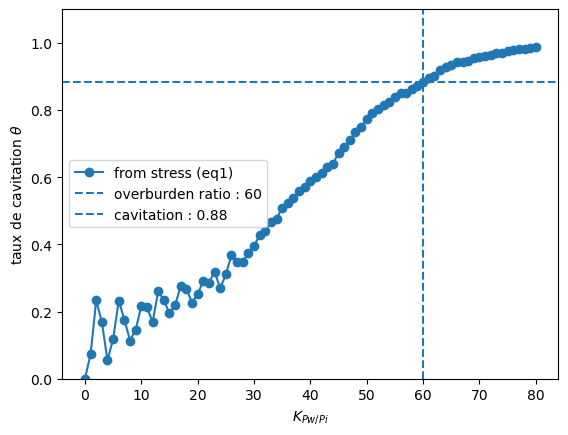

In [3]:

theta_nb_chosen = '60'
filename_chosen = 'sinus3dnS_1_14_'+theta_nb_chosen+'_0065__t0002'
path_name='../../data/sinus3dnS_1_14_0065/'+filename_chosen+'.csv'
data_chosen=pd.read_csv(path_name)

#by default : 
threshold = 0.15 #m 
threshold_list = [0.01]#np.arange(0.197,0.203,0.001)
cavitation_pressure_list = np.arange(46,81,1)


kinematic_P_outlet_list, grad_eff_phi_list = f.initialisation()
# For 60 L != 13 but 14.6, so grad phi eff is slightly different : 
kinematic_P_outlet_list_for_60, grad_eff_phi_list_for_60 = initialisation_correc_for_60()

real_cavitation_chosen, real_cavitation_list, all_the_other_values, tau_b_chosen, A_s = f.compute_cavitation(data_chosen,theta_nb_chosen)
Kp_inlet = 631.76 #m2/s2

# Post-processing

In [4]:
# setup to post-process :
theta_nb_pp = "60"#theta_nb_chosen
trsh_str_pp = '15'#trsh_str
P_outlet_index = 2
P_out_val_pp=str(f'_kPout_{kinematic_P_outlet_list[P_outlet_index]:.0f}')

cavitation_val = real_cavitation_list[int(theta_nb_pp)]
print(cavitation_val)
file_name_pp = f'sinus3dnS_1_14_{theta_nb_pp}_0065__t0002_trsh_{trsh_str_pp}'


file_name_post = file_name_pp+P_out_val_pp
print(file_name_post)
directory_name_pp=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_pp
print(directory_name_pp)

0.8841703528668712
sinus3dnS_1_14_60_0065__t0002_trsh_15_kPout_621
3D_cavity_60_trsh_15_kPout_621


In [5]:
SS_startTime = 5000

#initialise the flowrate_df :
main_flowrate_df = None
init_dir = '621'
P_out_val_init=str(f'_kPout_{init_dir}')
directory_name_init=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_init

flowrate_df_init = f.get_flow_rates(directory_name_init,theta_nb_pp,trsh_str_pp,P_out_val_init,merge = True,files_to_merge=[0,3000])
main_flowrate_df = flowrate_df_init



#for i,kP_out in enumerate(kinematic_P_outlet_list):
for i,kP_out in enumerate(kinematic_P_outlet_list):
    Full_ds = {}
    P_out_val_it=str(f'_kPout_{kP_out:.0f}')
    print(f'--- processing the simulation for kP_out of {kP_out:.0f} m2/s2 ---\n')
    directory_name_it=f'3D_cavity_{theta_nb_pp}_trsh_{trsh_str_pp}'+P_out_val_it
    file_name_post_it = file_name_pp+P_out_val_it
    
    #Full_ds[f'trsh_{trsh_str_pp}{P_out_val_it}'] = f.get_sim_data(directory_name_it,theta_nb_pp,trsh_str_pp,b_coords,save=True,mean_val=True,yPlus=False,res=0.05,filename_save=file_name_post_it)
    
    if P_out_val_it == P_out_val_init :
        continue
    else :
        flowrate_df = f.get_flow_rates(directory_name_it,theta_nb_pp,trsh_str_pp,P_out_val_it,merge = True,files_to_merge=[3000,4500])
    

    main_flowrate_df = main_flowrate_df.join(flowrate_df.set_index("Time"), on="Time",how="outer")


main_flowrate_df_SS = main_flowrate_df[main_flowrate_df['Time'] >=SS_startTime].set_index('Time')
main_flowrate_df = main_flowrate_df.set_index('Time')

# Create a list of column names sorted by the numeric value at the end (descending)
sorted_cols = sorted(
    main_flowrate_df.columns, 
    key=lambda x: float(x.split('_')[-1]), 
    reverse=True
)

# Reorder the dataframe using this sorted list
main_flowrate_df = main_flowrate_df[sorted_cols]
main_flowrate_df_SS = main_flowrate_df_SS[sorted_cols]

flowrate_filename_save = f'flowrate_{file_name_pp}'
main_flowrate_df.to_csv(f'/home/grandafe/Documents/Stage/post_sim_data/{theta_nb_pp}/trsh_{trsh_str_pp}/{flowrate_filename_save}.csv')


--- processing the simulation for kP_out of 630 m2/s2 ---

--- processing the simulation for kP_out of 626 m2/s2 ---

--- processing the simulation for kP_out of 621 m2/s2 ---

--- processing the simulation for kP_out of 612 m2/s2 ---

--- processing the simulation for kP_out of 602 m2/s2 ---

--- processing the simulation for kP_out of 593 m2/s2 ---

--- processing the simulation for kP_out of 584 m2/s2 ---

--- processing the simulation for kP_out of 575 m2/s2 ---

--- processing the simulation for kP_out of 566 m2/s2 ---

--- processing the simulation for kP_out of 557 m2/s2 ---

--- processing the simulation for kP_out of 548 m2/s2 ---

--- processing the simulation for kP_out of 539 m2/s2 ---

--- processing the simulation for kP_out of 489 m2/s2 ---



In [6]:
SS_mean_flowrate = []
for column in main_flowrate_df_SS:
    SS_mean_flowrate.append(main_flowrate_df_SS[column].mean())

In [7]:
def effective_constriction_in_serie(a1,a2,pr1,pr2):
    Gr1 = np.sqrt(a1**3/pr1)
    Gr2 = np.sqrt(a2**3/pr2)
    num = Gr1 * Gr2
    dem = np.sqrt(Gr1**2 + Gr2**2)
    return num/dem


def circularity(a,pr):
    return 4*np.pi*a/pr**2


if   trsh_str_pp == '15' and  theta_nb_pp == "57": # en série so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.056, 0.178, 1.025, 2.336
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True
    
elif trsh_str_pp == '15' and  theta_nb_pp == "60": # remember it has a different L  # en série so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.134, 0.342, 1.888, 3.638
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True

    grad_phi_list_tmp = grad_eff_phi_list_for_60
    
elif trsh_str_pp == '15' and  theta_nb_pp == "65": # en série N=2 so fD_eff = 2*fD
    a1, a2, pr1, pr2 = 0.211, 0.294, 2.064, 3.481
    Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
    serie = True
    
elif trsh_str_pp == '15' and  theta_nb_pp == "70":
    a1, pr1 = 0.303,3.330
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)

elif trsh_str_pp == '10' and  theta_nb_pp == "70":
    a1, pr1 = 0.392,4.413
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)
    
elif trsh_str_pp == '15' and  theta_nb_pp == "75":
    a1, pr1 = 0.342,3.500
    Gr_eff = np.sqrt(a1**3/pr1)
    xi_circularity = circularity(a1,pr1)
    
elif trsh_str_pp == '15' and  theta_nb_pp == "80":
    a1, pr1 = 0.361,3.901
    Gr_1 = np.sqrt(a1**3/pr1)
    a2, pr2 = 0.210,2.115
    Gr_2 = np.sqrt(a2**3/pr2)
    a3, pr3 = 0.037,0.754
    Gr_3 = np.sqrt(a3**3/pr3)
    Gr_eff = Gr_1 + Gr_2 + Gr_3

geo_ratio=Gr_eff
print(geo_ratio)

0.033794254526563476


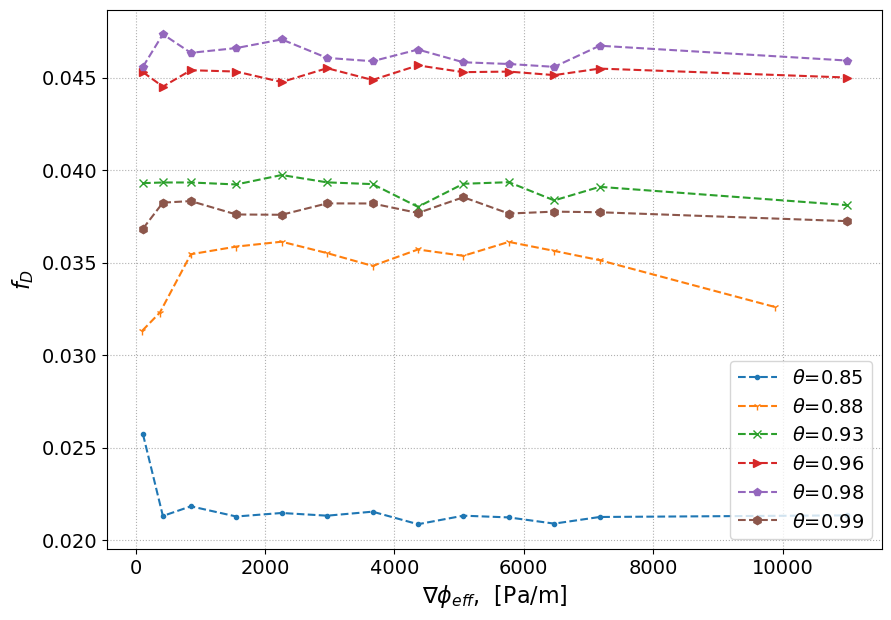

In [120]:


def fD_from_Bernoulli(flowrate,grad_phi,Gr_eff,N=1):
    rho_w=1000
    
    fD_eff = 8*grad_phi*Gr_eff**2/(flowrate**2*rho_w)
    
    return fD_eff * N


SS_startTime_1 = 5200

flowrate_dic_all_theta={}
fD_mean_list = []
fD_std_list = []
fD_mean_serie_list = []
Gr_eff_list = []

h_mean_list = []

linestyles = ['--.','--1','--x','-->','--p','--h']
theta_list_global = [ real_cavitation_list[57],real_cavitation_list[60],real_cavitation_list[65],real_cavitation_list[70],real_cavitation_list[75],real_cavitation_list[80]]


plt.figure(figsize=(10,7))
plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]',fontsize=16)
plt.ylabel(r'$f_D$',fontsize=16)

plt.yticks(fontsize=14)
plt.xticks(fontsize=14)


for j,kwi in enumerate(['57','60','65','70','75','80']) :
    path_to_csv_flow = f'/home/grandafe/Documents/Stage/post_sim_data/{kwi}/trsh_15/flowrate_sinus3dnS_1_14_{kwi}_0065__t0002_trsh_15.csv'
    
    tmp_flowrate_df = pd.read_csv(path_to_csv_flow)
    tmp_flowrate_df_SS = tmp_flowrate_df[tmp_flowrate_df['Time'] >=SS_startTime_1].set_index('Time')
    #flowrate_dic_all_theta[f'flow_Kwi_{kwi}'] = tmp_flowrate_df_SS
    SS_mean_flowrate_tmp = []
    for column in tmp_flowrate_df_SS:
        SS_mean_flowrate_tmp.append(tmp_flowrate_df_SS[column].mean())
    flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}'] = SS_mean_flowrate_tmp

    grad_phi_list_tmp = grad_eff_phi_list

    serie = False
    h_mean_list.append(all_the_other_values['h'][int(kwi)])


    if   trsh_str_pp == '15' and  kwi == "57": # en série so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.056, 0.178, 1.025, 2.336
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True
        
    elif trsh_str_pp == '15' and  kwi == "60": # remember it has a different L  # en série so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.134, 0.342, 1.888, 3.638
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True

        grad_phi_list_tmp = grad_eff_phi_list_for_60
        
    elif trsh_str_pp == '15' and  kwi == "65": # en série N=2 so fD_eff = 2*fD
        a1, a2, pr1, pr2 = 0.211, 0.294, 2.064, 3.481
        Gr_eff = effective_constriction_in_serie(a1,a2,pr1,pr2)
        serie = True
        
    elif trsh_str_pp == '15' and  kwi == "70":
        a1, pr1 = 0.303,3.330
        Gr_eff = np.sqrt(a1**3/pr1)
        
    elif trsh_str_pp == '15' and  kwi == "75":
        a1, pr1 = 0.342,3.500
        Gr_eff = np.sqrt(a1**3/pr1)
        
    elif trsh_str_pp == '15' and  kwi == "80":
        a1, pr1 = 0.361,3.901
        Gr_1 = np.sqrt(a1**3/pr1)
        a2, pr2 = 0.210,2.115
        Gr_2 = np.sqrt(a2**3/pr2)
        a3, pr3 = 0.037,0.754
        Gr_3 = np.sqrt(a3**3/pr3)
        Gr_eff = Gr_1 + Gr_2 + Gr_3

    if serie :
        flowrate_dic_all_theta[f'fD_Kwi_{kwi}']=fD_from_Bernoulli(np.array(flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}']),np.array(grad_phi_list_tmp),Gr_eff,N=1)
    else :
        flowrate_dic_all_theta[f'fD_Kwi_{kwi}']=fD_from_Bernoulli(np.array(flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}']),np.array(grad_phi_list_tmp),Gr_eff,N=1)
    fD_mean_list.append(flowrate_dic_all_theta[f'fD_Kwi_{kwi}'].mean())
    fD_std_list.append(flowrate_dic_all_theta[f'fD_Kwi_{kwi}'].std())
    
    Gr_eff_list.append(Gr_eff)
    
    plt.plot(grad_phi_list_tmp,flowrate_dic_all_theta[f'fD_Kwi_{kwi}'],linestyles[j],label=rf'$\theta$={theta_list_global[j]:.2f}')
plt.legend()


plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend(fontsize=14)
plt.show()

plt.show()

In [9]:
a1, pr1 = 0.394,4.489
np.sqrt(a1**3/pr1)

np.float64(0.116726517866627)

In [10]:
mean_fD = np.array(fD_mean_list).mean()
margin_fD = 2*np.array(fD_mean_list).std()

print(f'fD = {mean_fD:.3e} +- {margin_fD:.3e}')




fD = 3.745e-02 +- 1.627e-02


/tmp/ipykernel_21371/3682661047.py:10: RuntimeWarning: divide by zero encountered in divide
  return C1*1/((1-x)**gamma )


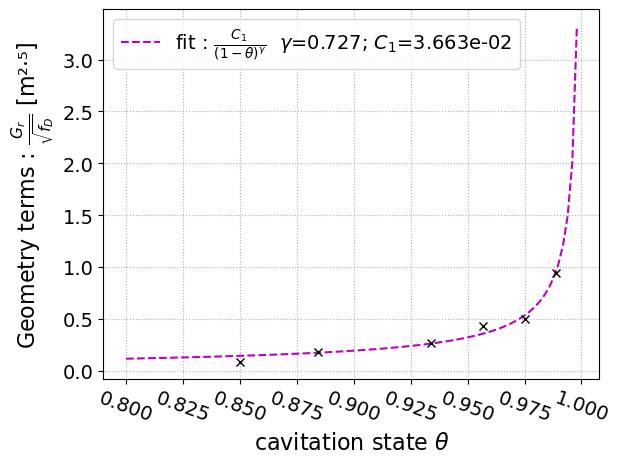

In [63]:
rho_w = 1000

theta_list_global = [ real_cavitation_list[57],real_cavitation_list[60],real_cavitation_list[65],real_cavitation_list[70],real_cavitation_list[75],real_cavitation_list[80]]

fit_style_chosen = 'schoof' # or 'schoof or 'gilbert'

if fit_style_chosen=='schoof' :
    def theta_2_Gr_law(x,gamma,C1):
        
        return C1*1/((1-x)**gamma )
        
if fit_style_chosen=='werder' :
    def theta_2_Gr_law(x,gamma,C1,C2):
        
        return C1*1/((1 + C2*(1-x))**gamma )
        
if fit_style_chosen=='gilbert' :   
    def theta_2_Gr_law(x,gamma,C1):
        
        return C1*x**gamma 
    
geometry_terms = np.array(Gr_eff_list)/np.array(np.sqrt(fD_mean_list))
Ks_halpha_list = []
for i,G_t in enumerate(geometry_terms) :
    if i == 1 :
        L=14.6
    else :
        L = 13.0
    Ks_halpha_list.append(G_t*np.sqrt(8/(rho_w*L**2)))

popt, pcov = curve_fit(theta_2_Gr_law,theta_list_global,geometry_terms)

X_theta = np.linspace(0.8,1,100)

if fit_style_chosen=='werder' :
    plt.plot(X_theta,theta_2_Gr_law(X_theta,popt[0],popt[1],popt[2]),'m--', label = r'fit : $\frac{C_1}{(1-\theta)^{\gamma}}$ ' + r' $\gamma$='+f'{popt[0]:.3f}' r'; $C_1$='+f'{popt[1]:.3e}' r'; $C_2$='+f'{popt[2]:.3e}')

else :
    plt.plot(X_theta,theta_2_Gr_law(X_theta,popt[0],popt[1]),'m--', label = r'fit : $\frac{C_1}{(1-\theta)^{\gamma}}$ ' + r' $\gamma$='+f'{popt[0]:.3f}' r'; $C_1$='+f'{popt[1]:.3e}')


plt.plot(theta_list_global,geometry_terms,'kx')

plt.xlabel(r'cavitation state $\theta$', fontsize=16)
plt.ylabel(r'Geometry terms : $\frac{G_r}{\sqrt{f_D}}$ [m²·⁵]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14,rotation=-20)
plt.grid(ls=':')
plt.legend(fontsize=14)

/tmp/ipykernel_21371/3682661047.py:10: RuntimeWarning: divide by zero encountered in divide
  return C1*1/((1-x)**gamma )


(0.0, 0.01)

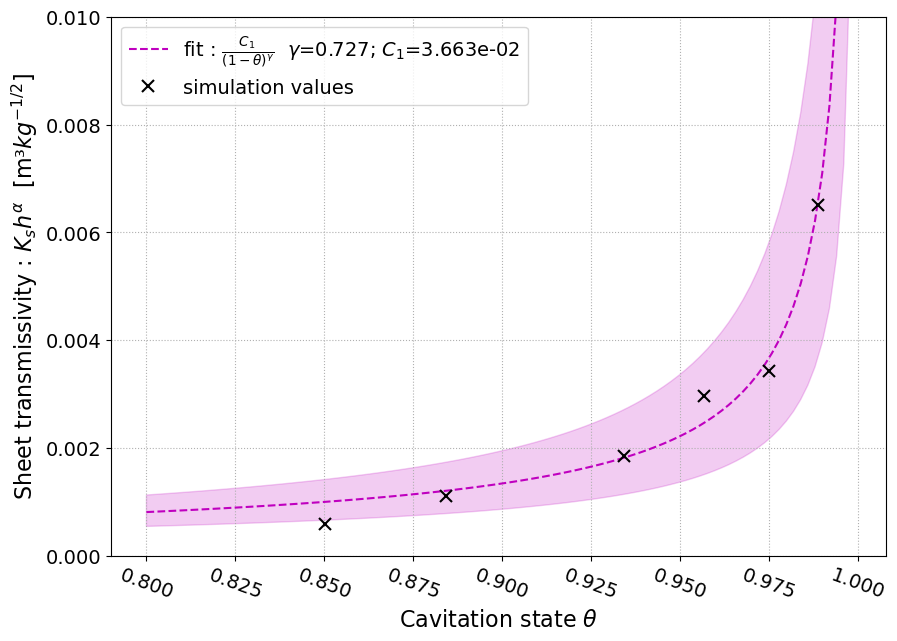

In [119]:
X_theta = np.linspace(0.8,1,100)
plt.figure(figsize=(10, 7))

lower_bound = theta_2_Gr_law(X_theta, C1 = fit_coefs[1] -  uncertainties[1], gamma = fit_coefs[0] -  uncertainties[0])*np.sqrt(8/(rho_w*13**2))
upper_bound = theta_2_Gr_law(X_theta, C1 = fit_coefs[1] +  uncertainties[1], gamma = fit_coefs[0] +  uncertainties[0])*np.sqrt(8/(rho_w*13**2))


if fit_style_chosen=='werder' :
    plt.plot(X_theta,theta_2_Gr_law(X_theta,popt[0],popt[1],popt[2]),'m--', label = r'fit : $\frac{C_1}{(1-\theta)^{\gamma}}$ ' + r' $\gamma$='+f'{popt[0]:.3f}' r'; $C_1$='+f'{popt[1]:.3e}' r'; $C_2$='+f'{popt[2]:.3e}')

else :
    plt.plot(X_theta,theta_2_Gr_law(X_theta,popt[0],popt[1])*np.sqrt(8/(rho_w*13**2)),'m--',linewidth=1.5, label = r'fit : $\frac{C_1}{(1-\theta)^{\gamma}}$ ' + r' $\gamma$='+f'{popt[0]:.3f}' r'; $C_1$='+f'{popt[1]:.3e}')


plt.fill_between(X_theta, lower_bound, upper_bound, color='m', alpha=0.2)

plt.plot(theta_list_global,Ks_halpha_list,'kx', label='simulation values',markersize=8,mew=1.5)

plt.xlabel(r'Cavitation state $\theta$', fontsize=16)
plt.ylabel(r'Sheet transmissivity : $K_s h^{\alpha}$  [m³$kg^{-1/2}$]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14,rotation=-20)
plt.grid(ls=':')
plt.legend(fontsize=14)
plt.ylim(0,0.010)

In [45]:
popt

array([0.72656076, 0.03662685])

In [109]:
fit_coefs = popt
uncertainties = np.sqrt(np.diag(pcov)) 



def darcy_weisbach_theta(grad_phi,theta,C1=fit_coefs[1],gamma= fit_coefs[0]):
    
    rho_w = 1000
    
    return theta_2_Gr_law(theta,gamma,C1) * np.sqrt(8*grad_phi/(rho_w))

    
tau_b_list_global = []
N_list_global = []
for i in [57,60,65,70,75,80] :
    tau_b_list_global.append(all_the_other_values['tau_b'][i])
    N_list_global.append(all_the_other_values['N_norm'][i])


In [51]:
pcov

array([[ 3.94461986e-03, -5.81415410e-04],
       [-5.81415410e-04,  8.80484543e-05]])

In [52]:
uncertainties

array([0.06280621, 0.00938341])

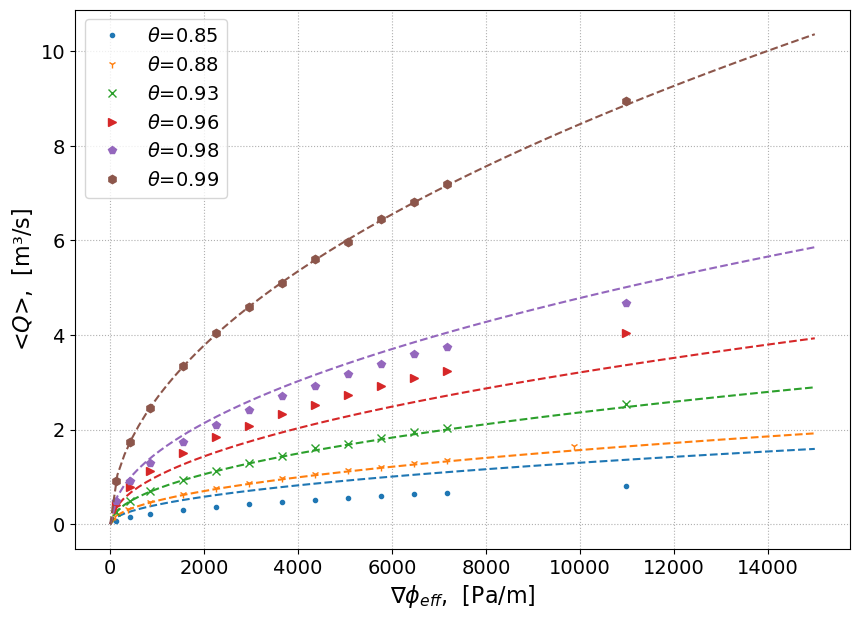

In [53]:
X = np.linspace(0, 15000, 100)
plt.figure(figsize=(10, 7))
linestyles = ['.','1','x','>','p','h']
for j, kwi in enumerate(['57', '60', '65', '70', '75', '80']):
    flowrate_tmp = np.array(flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}'])
    theta_tmp = theta_list_global[j]


    if kwi == '60' :
        p = plt.plot(grad_eff_phi_list_for_60, flowrate_tmp, linestyles[j], label=rf'$\theta$={theta_list_global[j]:.2f}')
    else :
        p = plt.plot(grad_eff_phi_list, flowrate_tmp, linestyles[j], label=rf'$\theta$={theta_list_global[j]:.2f}')
    
    # 2. Extract the color of the points
    current_color = p[0].get_color()

    # 3. Pass that color to the fit plot
    plt.plot(X, darcy_weisbach_theta(X, theta_tmp), '--', color=current_color)

plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
plt.ylabel(r'<$Q$>,  [m³/s]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend(fontsize=14)
# plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/grad_hydrau_vs_flowrate')
plt.show()
    

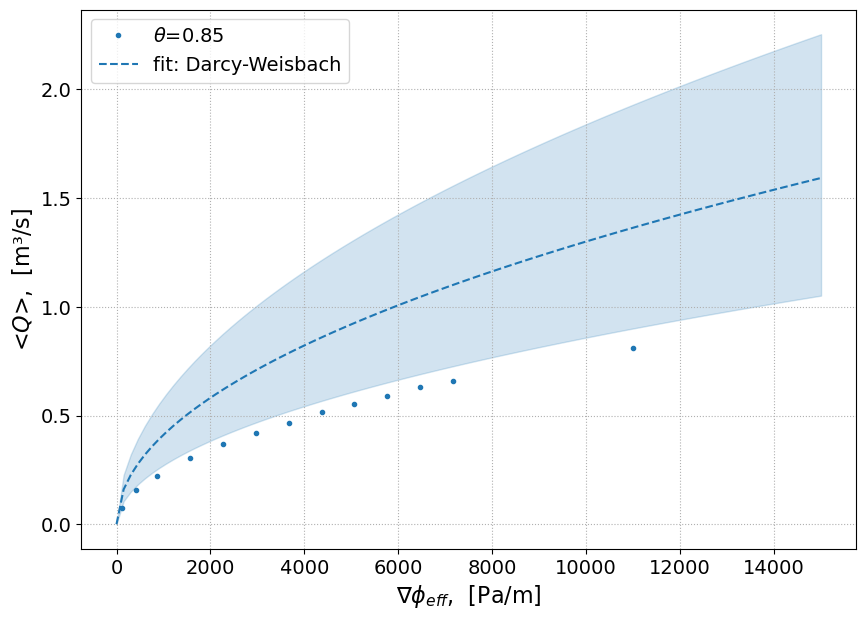

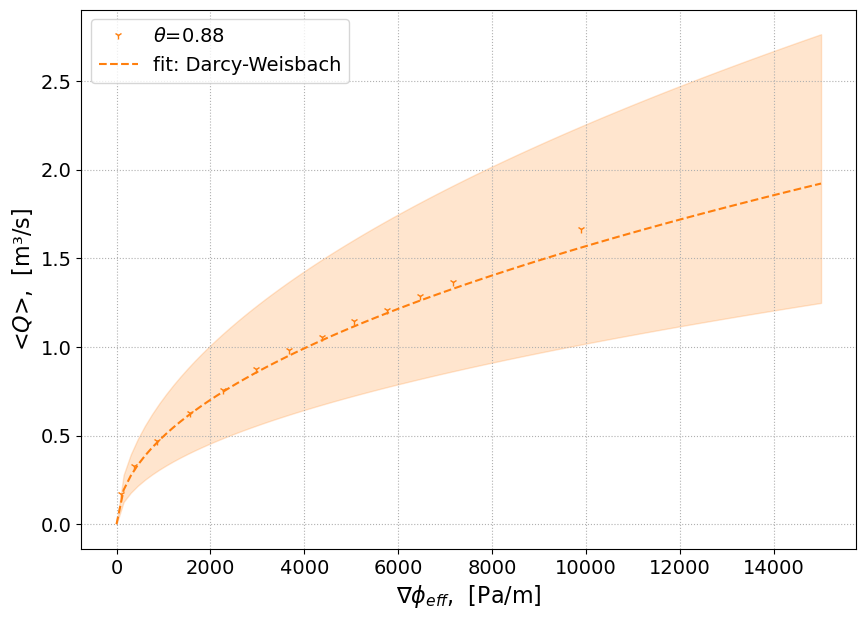

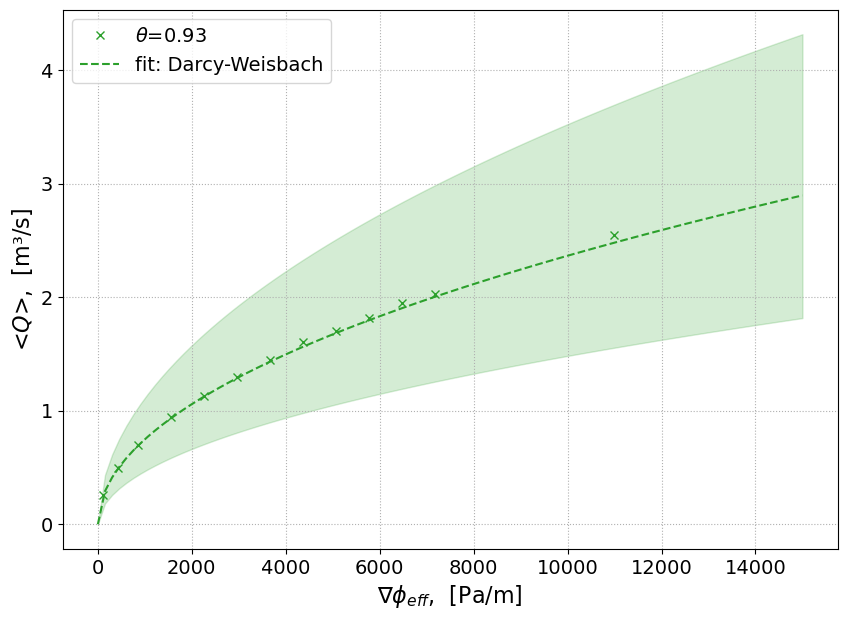

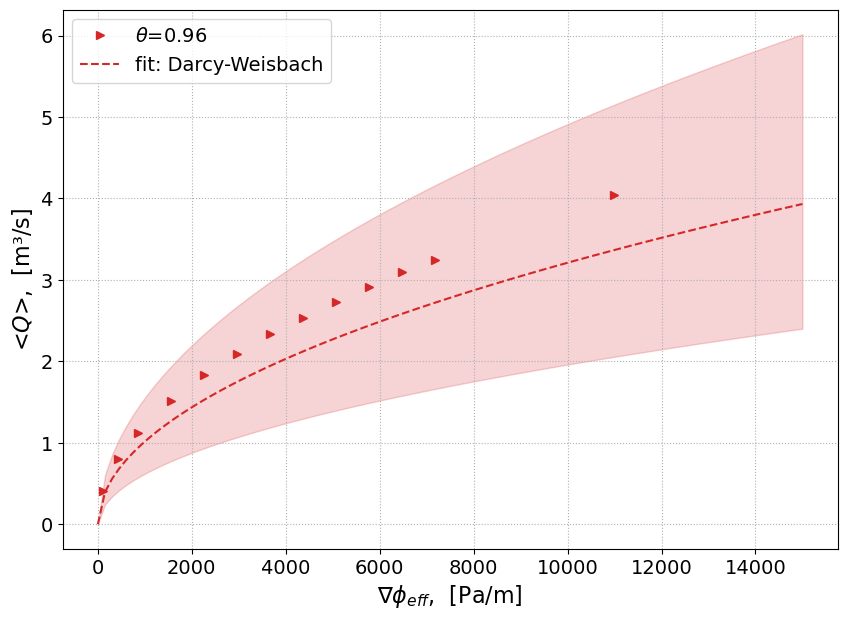

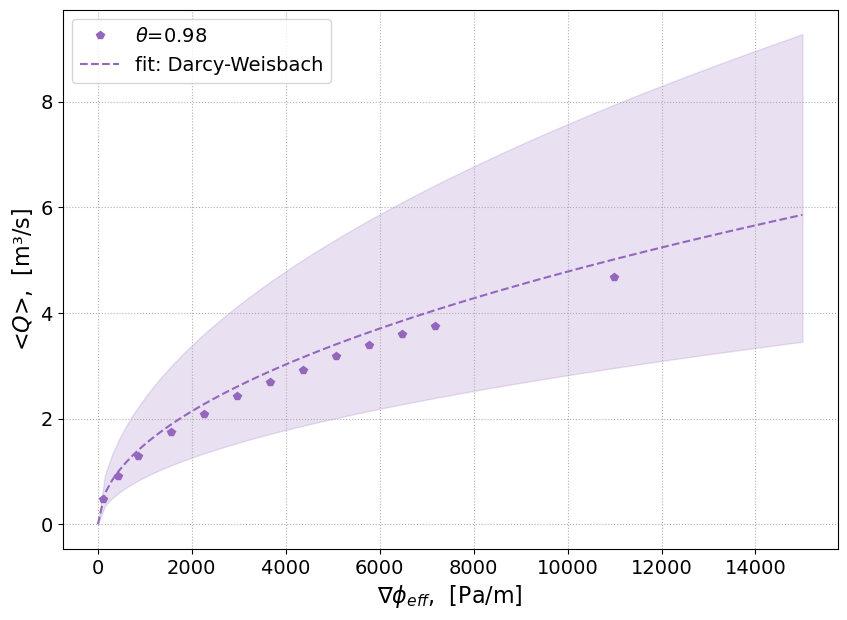

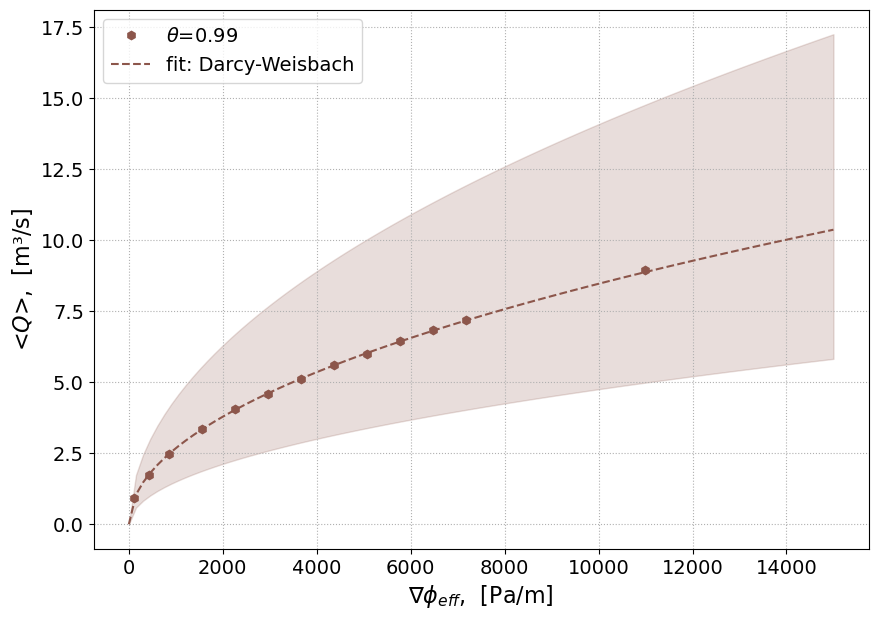

In [17]:
X = np.linspace(0, 15000, 100)

# Extract Matplotlib's default color cycle list
default_colors = plt.rcParams['axes.prop_cycle'].by_key()['color']
linestyles = ['.','1','x','>','p','h']
for j, kwi in enumerate(['57', '60', '65', '70', '75', '80']):
    plt.figure(figsize=(10, 7))
    flowrate_tmp = flowrate_dic_all_theta[f'SS_mean_flow_Kwi_{kwi}']
    theta_tmp = theta_list_global[j]

    # Select the color for the current iteration (using modulo for safety if >10 items)
    current_color = default_colors[j % len(default_colors)]

    lower_bound = darcy_weisbach_theta(X, theta_tmp, C1 = fit_coefs[1] -  uncertainties[1], gamma = fit_coefs[0] -  uncertainties[0])
    upper_bound = darcy_weisbach_theta(X, theta_tmp, C1 = fit_coefs[1] +  uncertainties[1], gamma = fit_coefs[0] +  uncertainties[0])

    # 1. Plot the simulated data points, explicitly passing our extracted color
    if kwi == '60' :
        plt.plot(grad_eff_phi_list_for_60, flowrate_tmp, linestyles[j], color=current_color, label=rf'$\theta$={theta_list_global[j]:.2f}')
    else :
        plt.plot(grad_eff_phi_list, flowrate_tmp, linestyles[j], color=current_color, label=rf'$\theta$={theta_list_global[j]:.2f}')
    
    # 2. Pass the exact same color to the fit plot and fill_between
    plt.plot(X, darcy_weisbach_theta(X, theta_tmp), '--', color=current_color,label=f'fit: Darcy-Weisbach')
    plt.fill_between(X, lower_bound, upper_bound, color=current_color, alpha=0.2)
    
    plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
    plt.ylabel(r'<$Q$>,  [m³/s]', fontsize=16)
    plt.yticks(fontsize=14)
    plt.xticks(fontsize=14)
    plt.grid(ls=':')
    plt.legend(fontsize=14)
    
    # Note: If you uncomment savefig, add the Kwi variable to the filename 
    # so it doesn't overwrite the same image 6 times!
    plt.savefig(f'/home/grandafe/Documents/Stage/img/report/{kwi}/Q_grad_phi_{kwi}.png')
    
    plt.show()

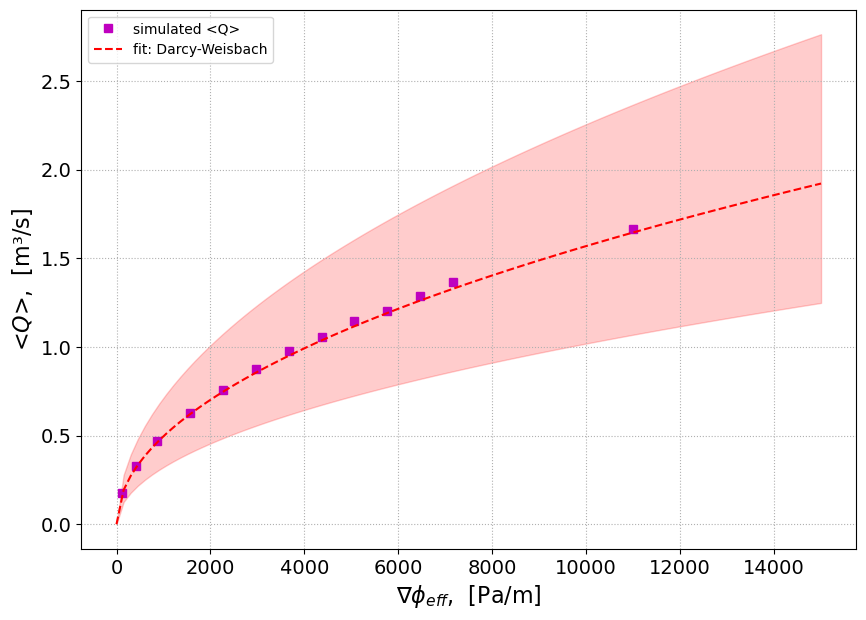

In [18]:


X = np.linspace(0, 15000, 100)

lower_bound = darcy_weisbach_theta(X, cavitation_val, C1 = fit_coefs[1] - uncertainties[1], gamma = fit_coefs[0] - uncertainties[0])
upper_bound = darcy_weisbach_theta(X, cavitation_val, C1 = fit_coefs[1] + uncertainties[1], gamma = fit_coefs[0] + uncertainties[0])


plt.figure(figsize=(10, 7))

# Plot the simulated data points
plt.plot(grad_eff_phi_list, SS_mean_flowrate, 'ms', label='simulated <Q>')


plt.plot(X, darcy_weisbach_theta(X, cavitation_val), 'r--', 
        label=f'fit: Darcy-Weisbach')

# Add the shaded uncertainty band
plt.fill_between(X, lower_bound, upper_bound, color='red', alpha=0.2)

plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
plt.ylabel(r'<$Q$>,  [m³/s]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend()
# plt.savefig('/home/grandafe/Documents/Stage/img/point_23_06/grad_hydrau_vs_flowrate')
plt.show()

In [19]:
geometry_terms_from_theta = theta_2_Gr_law(np.array(theta_list_global),C1=fit_coefs[1],gamma= fit_coefs[0])


(geometry_terms_from_theta - (geometry_terms)) / (geometry_terms_from_theta + (geometry_terms)) *100

array([25.67802433, -1.6425125 , -0.6788994 , -9.00044545,  3.6439607 ,
       -0.07139945])

In [20]:
geometry_terms_from_theta

array([0.14538155, 0.17538459, 0.26431686, 0.35891352, 0.534729  ,
       0.94581806])

In [21]:
geometry_terms

array([0.08597401, 0.18124223, 0.26793028, 0.42991127, 0.49712852,
       0.94716964])

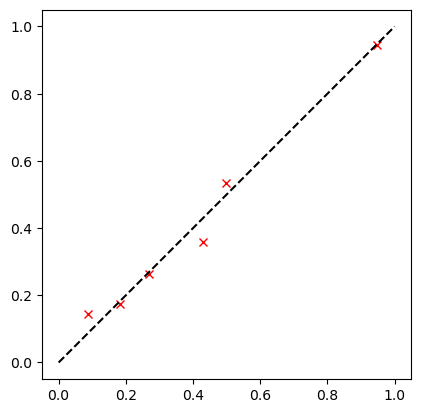

In [22]:
X2 = np.linspace(0,1,10)

fig1, ax = plt.subplots()
ax.plot(geometry_terms,geometry_terms_from_theta,'rx')
ax.plot(X2,X2,'k--')
ax.set_box_aspect(1)

plt.show()


In [100]:
h_mean_list

[np.float64(0.2306966210030303),
 np.float64(0.2645020381813476),
 np.float64(0.33189081574207985),
 np.float64(0.3935546671806474),
 np.float64(0.46404441618698283),
 np.float64(0.5341190939171487)]

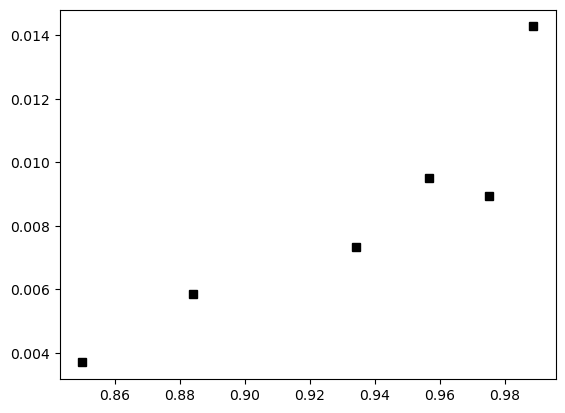

In [101]:
def ks_from_eq(G_t,L,h):
    alpha = 5/4
    rho_w=1000
    
    return G_t*np.sqrt(8/(rho_w*L**2))/(h**alpha)

L_list = np.array([13,14.6,13,13,13,13])

ks_list = ks_from_eq(geometry_terms,L_list,np.array(h_mean_list))


plt.plot(theta_list_global,ks_list,'ks')

In [102]:
ks_list

array([0.00369971, 0.0058535 , 0.00731778, 0.00948908, 0.0089304 ,
       0.0142719 ])

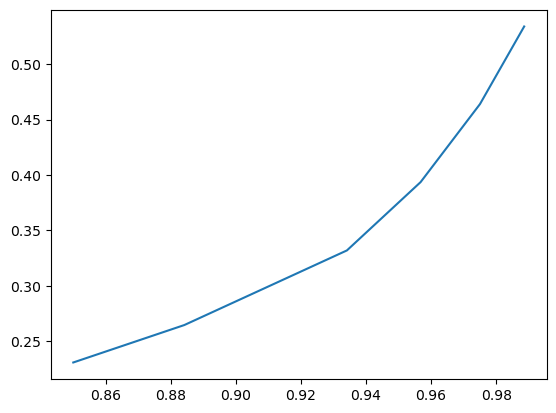

In [26]:

plt.plot(theta_list_global,h_mean_list)

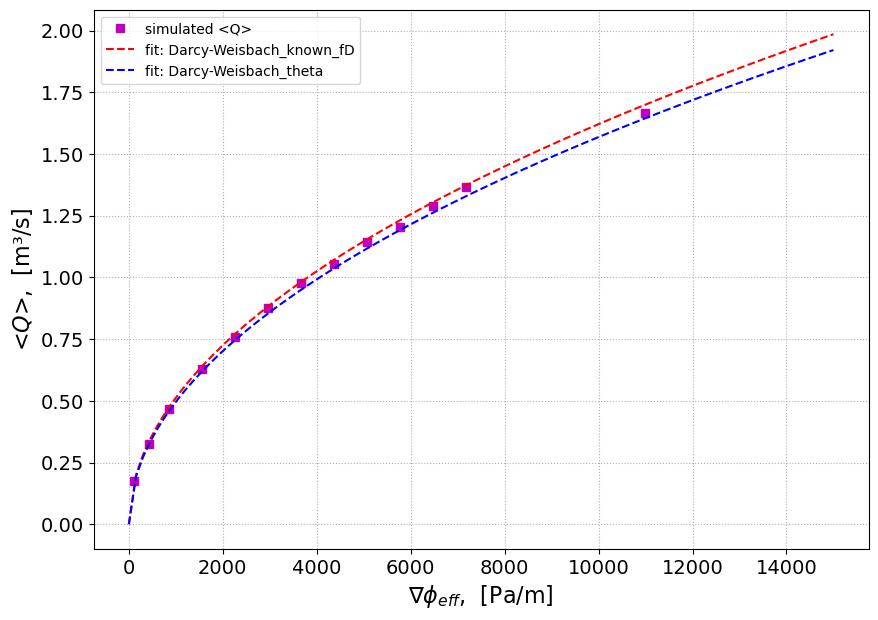

In [27]:
def DW_Gt(grad_phi,Gt):
    rho_w = 1000
    return Gt*np.sqrt(8*grad_phi/rho_w)

X = np.linspace(0, 15000, 100)



plt.figure(figsize=(10, 7))

# Plot the simulated data points
plt.plot(grad_eff_phi_list, SS_mean_flowrate, 'ms', label='simulated <Q>')

plt.plot(X, DW_Gt(X, geometry_terms[1]), 'r--', 
             label=f'fit: Darcy-Weisbach_known_fD')
plt.plot(X, DW_Gt(X, geometry_terms_from_theta[1]), 'b--', 
             label=f'fit: Darcy-Weisbach_theta')


plt.xlabel(r'$\nabla\phi_{eff}$,  [Pa/m]', fontsize=16)
plt.ylabel(r'<$Q$>,  [m³/s]', fontsize=16)
plt.yticks(fontsize=14)
plt.xticks(fontsize=14)
plt.grid(ls=':')
plt.legend()
plt.show()

In [28]:
print(f'for K_wi=80, The min/max mesh resolution (computed from the min/max cell volumes) : from {2e-8**(1/3)*100:.2e} to {4.5e-4**(1/3)*100:.2e} cm')

print(f'for K_wi=80, The min/max mesh resolution (computed from the min/max cell volumes) : from {5e-6**(1/3)*100:.2e} to {1.69e-2**(1/3)*100:.2e} cm')

for K_wi=80, The min/max mesh resolution (computed from the min/max cell volumes) : from 2.71e-01 to 7.66e+00 cm
for K_wi=80, The min/max mesh resolution (computed from the min/max cell volumes) : from 1.71e+00 to 2.57e+01 cm
